In [1]:
from google.cloud import bigquery
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

client = bigquery.Client(project="payflow-analytics-513907")

df = client.query("""
    SELECT *
    FROM `payflow-analytics-513907.payflow_analytics.gold_fraud_features`
""").to_dataframe()

print(f"Rows: {len(df):,}  |  Fraud rate: {df['is_fraud'].mean():.2%}")

Rows: 100,133  |  Fraud rate: 19.80%


## Overview

In [2]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
transaction_id,100133,100133,a668a8e7-d8d4-488e-b847-09ca509f756c,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_id,100133,3133,414679ac-7907-4d5f-af68-4428f84b0fbb,116,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,100133.0,NaN,NaN,NaN,170.363525,0.35,16.32,63.8,167.55,15015.63,419.86523
amount_usd,100133.0,NaN,NaN,NaN,113.771902,0.000963,1.05,13.2557,96.9,15219.970254,373.692402
currency,100133,5,MXN,20144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant,100133,61,UBER*TRIP,1743,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant_clean,100133,10,Shell,10267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mcc_code,100133,10,5541,10267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mcc_category,100133,10,automotive,10267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
risk_tier,100133,4,low,30435,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Fraud rate trend

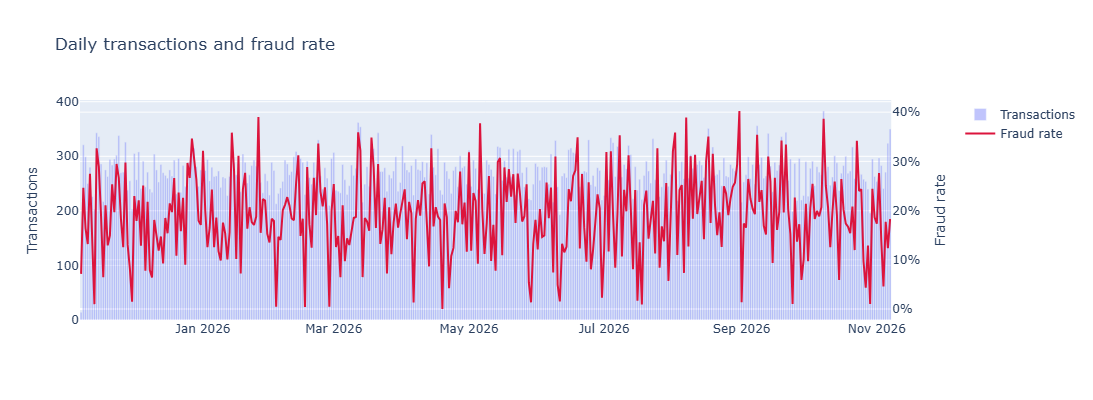

In [3]:
daily = (
    df.groupby("transaction_date")
    .agg(
        total=("transaction_id", "count"),
        fraud=("is_fraud", "sum"),
        total_usd=("amount_usd", "sum"),
    )
    .assign(fraud_rate=lambda x: x["fraud"] / x["total"])
    .reset_index()
)

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=daily["transaction_date"], y=daily["total"], name="Transactions", opacity=0.4), secondary_y=False)
fig.add_trace(go.Scatter(x=daily["transaction_date"], y=daily["fraud_rate"], name="Fraud rate", line=dict(color="crimson", width=2)), secondary_y=True)
fig.update_layout(title="Daily transactions and fraud rate", height=400)
fig.update_yaxes(title_text="Transactions", secondary_y=False)
fig.update_yaxes(title_text="Fraud rate", tickformat=".0%", secondary_y=True)
fig.show()

## Amount distribution: fraud vs legit

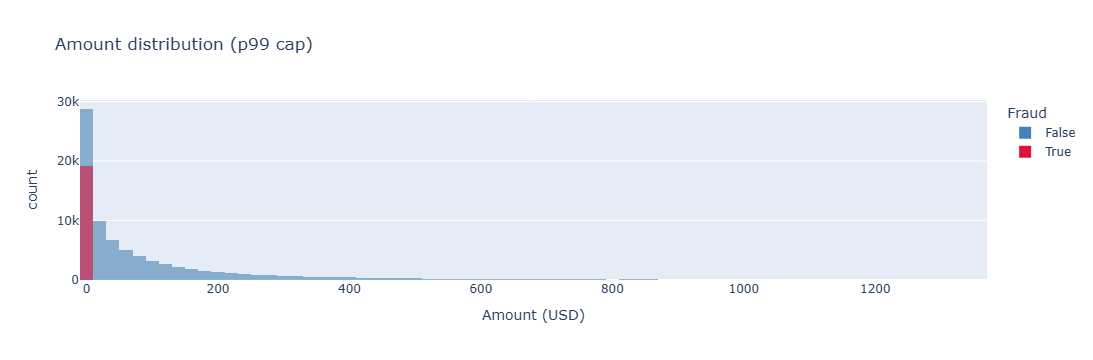

In [4]:
fig = px.histogram(
    df[df["amount_usd"] < df["amount_usd"].quantile(0.99)],
    x="amount_usd",
    color="is_fraud",
    nbins=80,
    barmode="overlay",
    opacity=0.6,
    color_discrete_map={True: "crimson", False: "steelblue"},
    labels={"amount_usd": "Amount (USD)", "is_fraud": "Fraud"},
    title="Amount distribution (p99 cap)",
)
fig.show()

## Fraud rate by feature

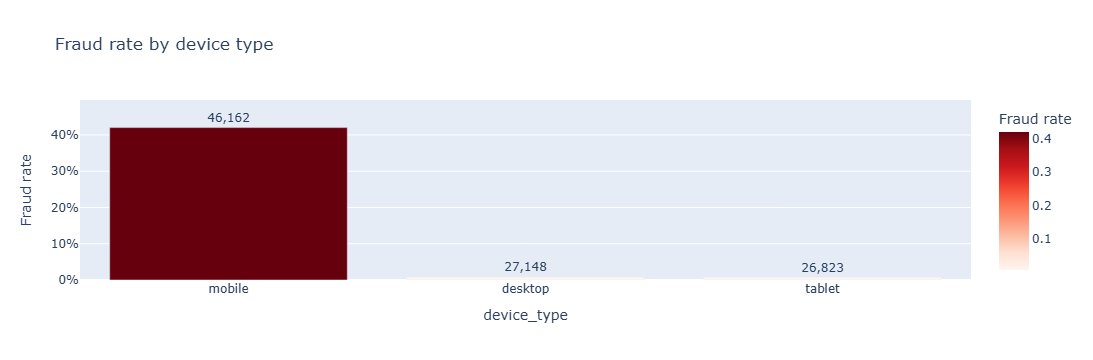

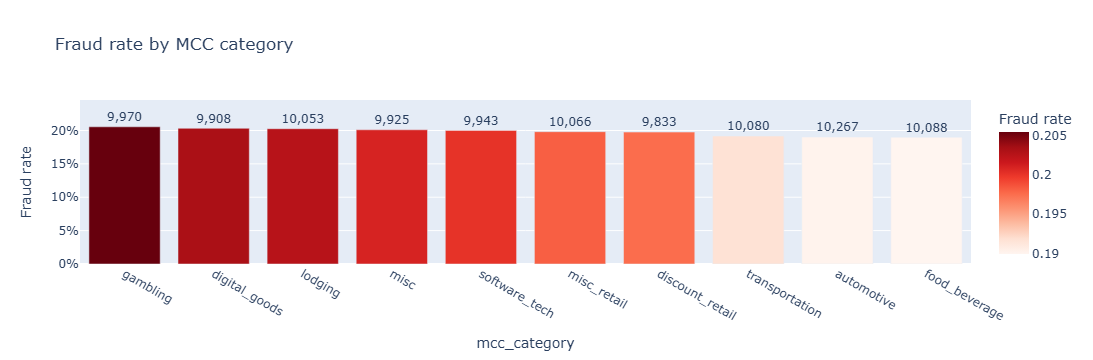

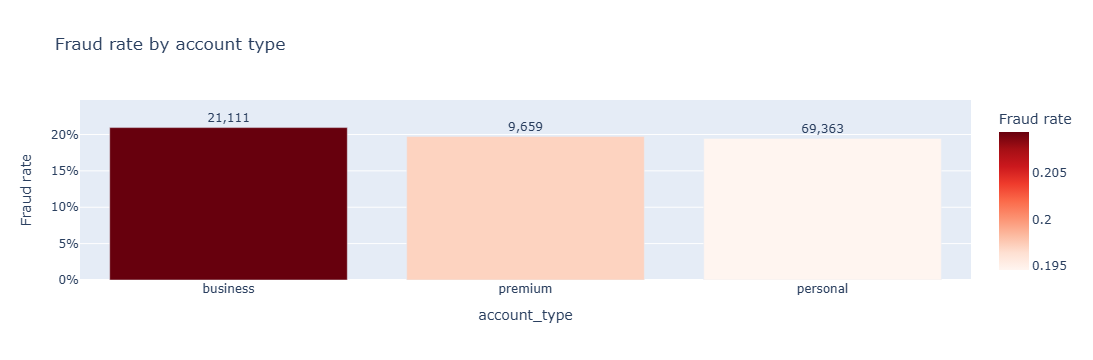

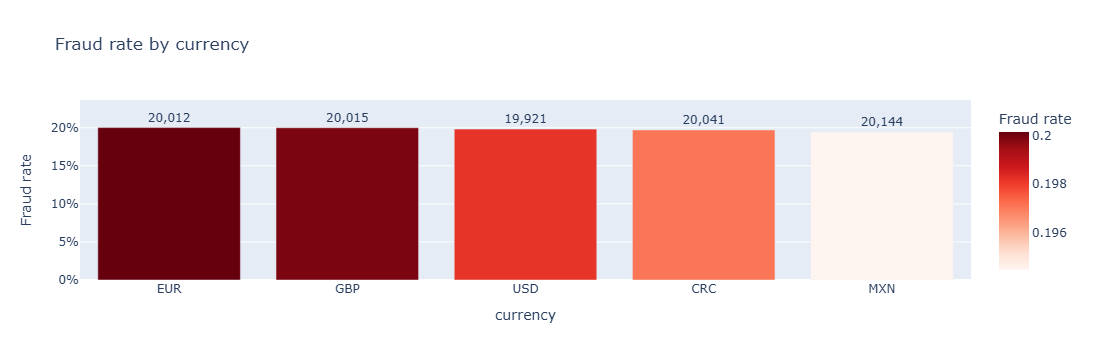

In [5]:
def fraud_rate_bar(col, title):
    agg = (
        df.groupby(col)["is_fraud"]
        .agg(["mean", "count"])
        .rename(columns={"mean": "fraud_rate", "count": "n"})
        .sort_values("fraud_rate", ascending=False)
        .reset_index()
    )
    fig = px.bar(
        agg, x=col, y="fraud_rate", text="n",
        title=title,
        labels={"fraud_rate": "Fraud rate"},
        color="fraud_rate",
        color_continuous_scale="Reds",
    )
    fig.update_yaxes(tickformat=".0%")
    fig.update_traces(texttemplate="%{text:,}", textposition="outside")
    fig.show()

fraud_rate_bar("device_type", "Fraud rate by device type")
fraud_rate_bar("mcc_category", "Fraud rate by MCC category")
fraud_rate_bar("account_type", "Fraud rate by account type")
fraud_rate_bar("currency", "Fraud rate by currency")

## Fraud by hour of day

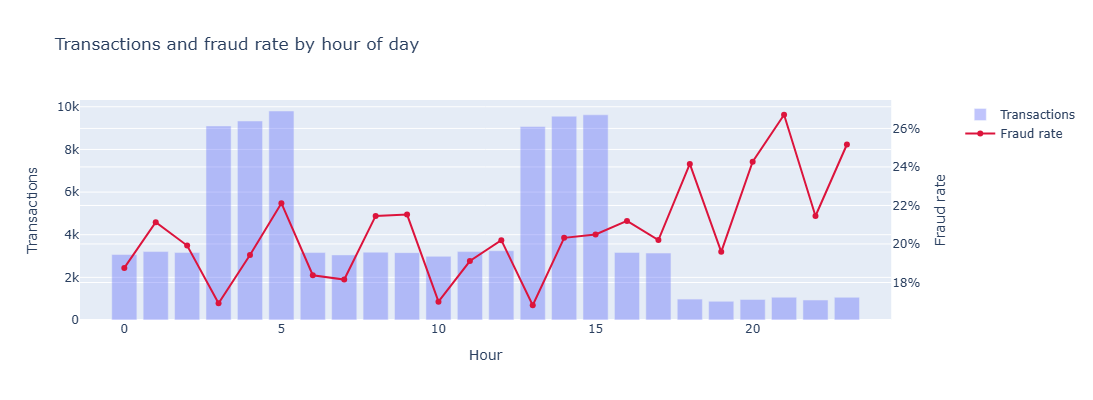

In [6]:
hourly = (
    df.groupby("hour_of_day")["is_fraud"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "fraud_rate", "count": "n"})
    .reset_index()
)

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=hourly["hour_of_day"], y=hourly["n"], name="Transactions", opacity=0.4), secondary_y=False)
fig.add_trace(go.Scatter(x=hourly["hour_of_day"], y=hourly["fraud_rate"], name="Fraud rate", line=dict(color="crimson", width=2), mode="lines+markers"), secondary_y=True)
fig.update_layout(title="Transactions and fraud rate by hour of day", xaxis_title="Hour", height=400)
fig.update_yaxes(title_text="Transactions", secondary_y=False)
fig.update_yaxes(title_text="Fraud rate", tickformat=".0%", secondary_y=True)
fig.show()

## Fraud patterns

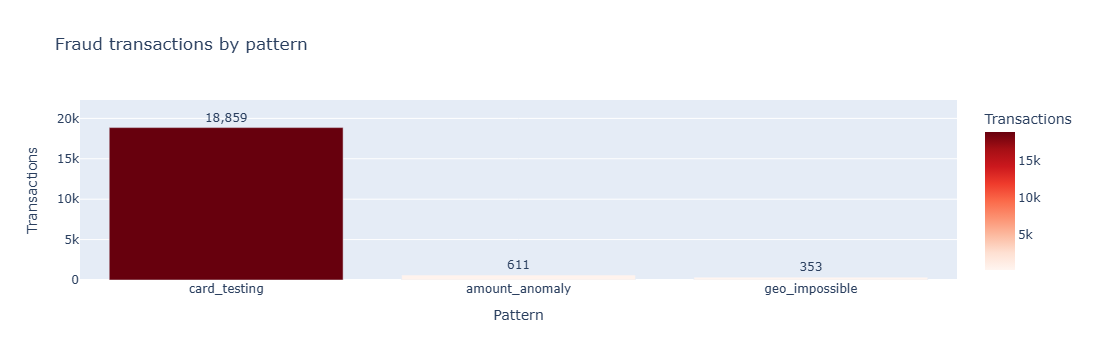

In [7]:
patterns = (
    df[df["is_fraud"]]
    .groupby("fraud_pattern", dropna=False)
    .size()
    .rename("count")
    .reset_index()
    .sort_values("count", ascending=False)
)
patterns["fraud_pattern"] = patterns["fraud_pattern"].fillna("unknown")

fig = px.bar(
    patterns, x="fraud_pattern", y="count",
    title="Fraud transactions by pattern",
    labels={"fraud_pattern": "Pattern", "count": "Transactions"},
    color="count",
    color_continuous_scale="Reds",
)
fig.update_traces(texttemplate="%{y:,}", textposition="outside")
fig.show()

## Numeric feature correlations with fraud

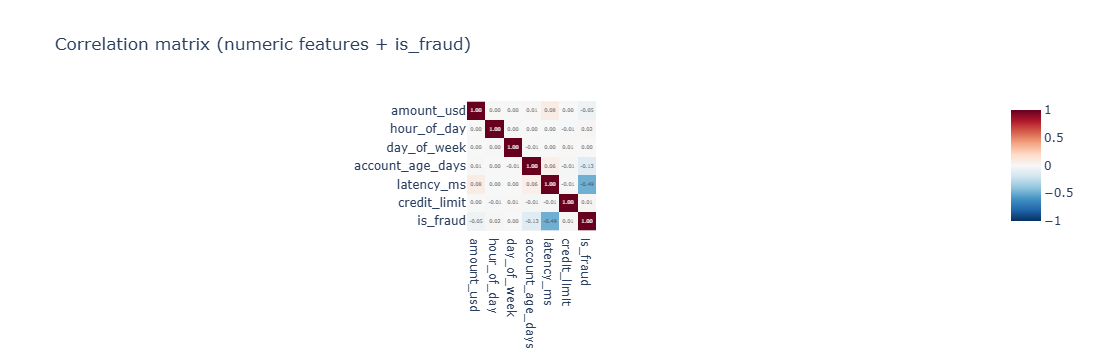

In [8]:
numeric_cols = ["amount_usd", "hour_of_day", "day_of_week", "account_age_days", "latency_ms", "credit_limit"]

corr = (
    df[numeric_cols + ["is_fraud"]]
    .assign(is_fraud=df["is_fraud"].astype(float))
    .corr()
)

fig = px.imshow(
    corr,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1, zmax=1,
    title="Correlation matrix (numeric features + is_fraud)",
)
fig.show()